# 05 · Accuracy improvements: shifting endpoints and persistent fitting errors

Notebooks 02–04 found that no model beats the forward curve, and README §7.6
traced the losses to four failures. This notebook tests the fixes for the
first two (README §8, step 7b, items 1–2):

1. **Persistent fitting errors.** Three Nelson–Siegel factors cannot match
   the published curves at 3m and 10y, and the misfit changes slowly. The
   plain forecast Λf̂ throws it away. Fix: an AR(1) for each maturity's
   filtered residual, added to the forecast: ρʰeₜ (`ar1`), or
   m + ρʰ(eₜ − m) with an intercept (`ar1c`, Raviv 2013).
2. **Mean reversion to a fixed mean.** μ is the average since 1985, 1993 or
   2004, and rates fell through every window, so the level kept forecasting a
   rebound. Fix: a shifting endpoint for the level, which the factors revert
   to instead (van Dijk, Koopman, van der Wel & Wright 2014):
   `ewma`, exponential smoothing of the level factor (α = 0.1 a month);
   `bond10` and `cpi10`, the Philadelphia Fed SPF's expected 10-year yield
   and 10-year CPI inflation (USD); `hicp_lt`, the ECB SPF's longer-term
   HICP expectation (EUR).

**The grid was fixed before anything was run** (README §8 step 7b; commit
`65d0165`, before any results existed): yields only and yields + policy rate,
each with every endpoint available for the currency and every error model,
24 USD, 18 EUR and 12 GBP backtests. All are reported below. Because many
variants are compared, §6 adds a model confidence set (Hansen, Lunde & Nason
2011) over every model from notebooks 02–05, which accounts for the search.

How it is implemented (`yck.model.adjust`):

- **Endpoint by detrending.** The level's loading is 1 at every maturity, so
  reverting to μ + eₜ is the ordinary DNS model for yₜ − eₜ. The endpoint is
  subtracted from every yield and from the policy rate, the model is estimated
  and filtered as before (μ at the real-time sample mean), and the origin's
  eₜ is added back to the forecast, held flat. With an inflation endpoint,
  μ_level becomes the average real rate plus term premium.
- **Real time.** The EWMA at month s uses curves up to s only. A survey
  counts as known from the end of the second month of its quarter.
- **Errors.** At each origin, ρ (and m) are fitted by OLS on the filtered
  residuals up to the origin. No re-estimation is needed, so the `ar1`
  variants reuse the plain models' fits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from yck.model.adjust import fit_error_ar
from yck.model.dns import fit_factors
from yck.model.statespace_dns import fit_dns_mle
from yck.eval.backtest import dns_two_step_forecasts, random_walk_forecasts, forward_forecasts
from yck.eval.grid import (STANDARD_GRID, ENDPOINTS, ERROR_MODELS, accuracy_grid, ensure_results, load_endpoint,
                           run_tag, _grid_for)
from yck.eval.stats import dm_table, cw_table, mcs_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, CONFIG, DATA = ROOT / "data/results", ROOT / "config/data_sources.yaml", ROOT / "data"
CCYS = ["USD", "EUR", "GBP"]
EST_START = {"USD": "1985-01-31", "EUR": "2004-09-30", "GBP": "1993-01-31"}
FIRST_ORIGIN = {"USD": "2000-01-31", "EUR": "2010-01-31", "GBP": "2010-01-31"}
H = (1, 6, 12)
SHOW = {"USD": ["3m", "12m", "24m", "60m", "120m"], "EUR": ["3m", "12m", "24m", "60m", "120m"],
        "GBP": ["6m", "12m", "24m", "60m", "120m"]}  # GBP 3m: 39 published months since 2010 (notebook 04)
EP_LABEL = {None: "fixed μ", "ewma": "EWMA", "bond10": "SPF 10y yield", "cpi10": "SPF 10y CPI",
            "hicp_lt": "ECB SPF HICP"}
ERR_LABEL = {None: "", "ar1": " + AR(1)", "ar1c": " + AR(1) with mean"}
MODEL_LABEL = {None: "yields", ("policy_rate",): "policy rate"}

ensure_results(CCYS, DATA, CONFIG)                      # step 7 grid (for the model confidence set)
ensure_results(CCYS, DATA, CONFIG, grid=accuracy_grid)  # step 7b grid
y = {c: pd.read_parquet(ROOT / f"data/processed/curves_{c}.parquet").loc[EST_START[c]:] for c in CCYS}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def label(m, ep, err):
    return f"{MODEL_LABEL[m]}: {EP_LABEL[ep]}{ERR_LABEL[err]}"

fc, variants = {}, {}
for c in CCYS:
    fc[c] = {}
    for m, lam, tau, ep, err, _ in _grid_for(accuracy_grid, c):
        tag = run_tag(m, lam, tau, 1.0, ep, err)
        fc[c][label(m, ep, err)] = {h: pd.read_parquet(RESULTS / f"fc_{c}_kalman_{tag}_h{h}.parquet") for h in H}
    variants[c] = list(fc[c])
    for m, lam, tau, *_ in _grid_for(STANDARD_GRID, c):  # the other step 7 models, for the confidence set
        tag = run_tag(m, lam, tau)
        name = "step 7: " + tag.replace("_lamfixed", "").replace("lamfixed", "yields").replace("lamest", "yields, λ est.")
        if m in (None, ("policy_rate",)) and lam == "fixed" and tau is None:
            continue  # same as the plain step 7b variants
        fc[c][name] = {h: pd.read_parquet(RESULTS / f"fc_{c}_kalman_{tag}_h{h}.parquet") for h in H}
    fc[c]["two-step AR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["two-step VAR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c], kind="var1")
    fc[c]["random walk"] = random_walk_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["forwards"] = forward_forecasts(pd.read_parquet(ROOT / f"data/processed/curves_ext_{c}.parquet"),
                                          y[c].columns, H, FIRST_ORIGIN[c])
pd.DataFrame({c: {"step 7b variants": len(variants[c]), "models in the confidence set": len(fc[c])} for c in CCYS})

,USD,EUR,GBP
step 7b variants,24,18,12
models in the confidence set,34,28,22


## 1. The endpoints

Each panel shows the month-by-month two-step level factor (what the endpoint
replaces μ for), the EWMA endpoint and the survey endpoints, as known in real
time. The dashed line is the fixed μ of the last refit (the real-time sample
mean of the level).

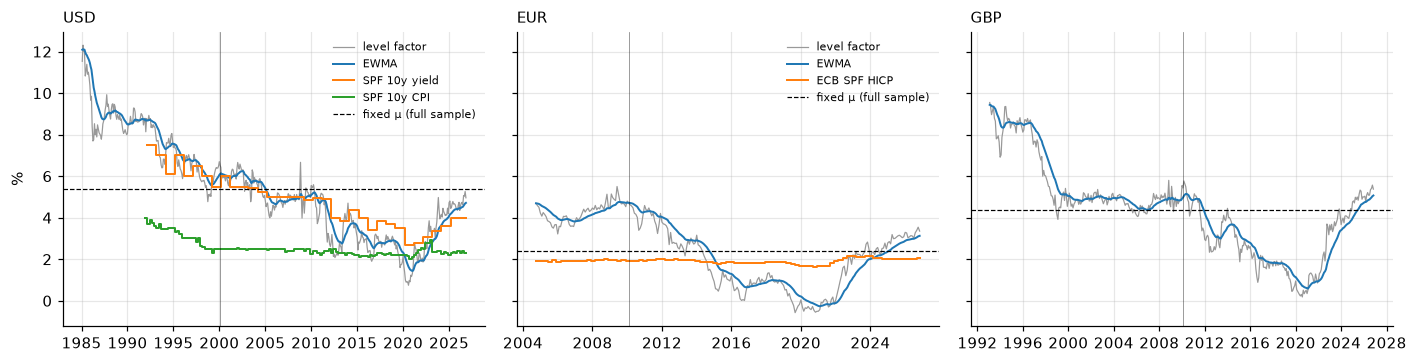

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, c in zip(axes, CCYS):
    full = pd.read_parquet(ROOT / f"data/processed/curves_{c}.parquet")
    level = fit_factors(y[c])["level"]
    ax.plot(level, lw=0.8, color="0.6", label="level factor")
    for ep in ENDPOINTS[c][1:]:
        e = load_endpoint(ep, c, full, DATA, CONFIG).loc[EST_START[c]:]
        ax.plot(e, lw=1.3, label=EP_LABEL[ep], drawstyle="steps-post" if ep != "ewma" else "default")
    ax.axhline(level.mean(), ls="--", color="k", lw=0.8, label="fixed μ (full sample)")
    ax.axvline(pd.Timestamp(FIRST_ORIGIN[c]), color="k", lw=0.5, alpha=0.5)
    ax.set_title(c, loc="left", fontsize=10)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=7, frameon=False)
axes[1].legend(fontsize=7, frameon=False); fig.tight_layout()

## 2. How persistent are the fitting errors?

The AR(1) fitted to each maturity's filtered residual by the plain
yields-only model, on the full sample (estimated once here for
illustration; the backtests refit at every origin on data up to that
origin). A ρ near 1 with a large standard deviation is a misfit that today's
residual predicts well; the plain forecast ignores it.

In [3]:
rows = {}
for c in CCYS:
    f = fit_dns_mle(y[c], n_starts=6)
    resid = y[c].to_numpy() - f.filtered_states(y[c]) @ f.statespace().Z.T
    m, rho = fit_error_ar(resid, "ar1c")
    sd = np.nanstd(resid, axis=0)
    for col in SHOW[c]:
        j = list(y[c].columns).index(col)
        rows[(c, col)] = {"residual sd (bp)": 100 * sd[j], "mean m (bp)": 100 * m[j], "ρ": rho[j],
                          "half-life (months)": np.log(0.5) / np.log(rho[j]) if 0 < rho[j] < 1 else np.nan}
pd.DataFrame(rows).T.round(2)

residual sd (bp)  mean m (bp)     ρ  half-life (months)
USD 3m               16.59        -9.22  0.54                1.13
    12m               0.30        -0.32  0.70                1.91
    24m               0.44        -0.20  0.60                1.34
    60m               3.85        -4.69  0.88                5.29
    120m              8.59        11.49  0.88                5.67
EUR 3m               14.30       -13.69  0.70                1.97
    12m               0.29        -0.40  0.16                0.38
    24m               0.41        -0.42  0.79                2.88
    60m               2.97        -6.04  0.82                3.39
    120m              6.62        13.43  0.87                5.10
GBP 6m               16.24         1.05  0.87                5.11
    12m               2.45        -0.67  0.88                5.38
    24m               0.55         0.28  0.89                5.84
    60m               3.37        -1.85  0.93                9.93
    120m             11.09         6.50  0.96               16.41

## 3. Every variant against forwards

RMSE relative to the forward-rate forecast (< 1: the model wins), with
Diebold–Mariano significance in either direction (* 10%, ** 5%, *** 1%).
Rows are model: endpoint + error model; the first row of each block is the
plain step 7 model. Forecast origins from 2000 (USD) and 2010 (EUR, GBP).
GBP has no forwards at h = 1 beyond 2 years (the 1m yield and the 61m+
points are not published), and its h = 1 forwards cover only 36 months,
because the BoE rarely publishes a 1m yield.

In [4]:
def after(c, h):
    return y[c].loc[pd.Timestamp(FIRST_ORIGIN[c]) + pd.offsets.MonthEnd(h):]

def vs(c, bench, h, names, field="cell"):
    t = dm_table({n: fc[c][n][h] for n in [bench] + names}, bench, after(c, h), h, SHOW[c])
    return t.xs(field, axis=1, level=1).T

for c in CCYS:
    t = pd.concat({f"h = {h}": vs(c, "forwards", h, variants[c]) for h in H}, axis=1)
    display(t.style.set_caption(f"{c}: RMSE / forwards").set_table_styles(
        [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]))

The same variants against the random walk (ratio only):

In [5]:
for c in CCYS:
    t = pd.concat({f"h = {h}": vs(c, "random walk", h, variants[c], "ratio").astype(float) for h in H}, axis=1)
    display(t.round(2).style.set_caption(f"{c}: RMSE / random walk").set_table_styles(
        [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]))

## 4. Does each fix help its own model?

Each change is tested against the model without it, on the same sample.

- **Error models** nest the plain model (ρ = 0, m = 0), so the test is
  Clark–West, one-sided in favour of the AR(1).
- **Endpoints** do not nest the fixed mean, so the test is Diebold–Mariano,
  two-sided. Each endpoint is compared with fixed μ, with no error model on
  either side.

Cells show the RMSE ratio, new / old.

In [6]:
def nested(c, h):
    rows = {}
    for m in MODEL_LABEL:
        for ep in ENDPOINTS[c]:
            base = label(m, ep, None)
            for err in ERROR_MODELS[1:]:
                t = cw_table({base: fc[c][base][h], "x": fc[c][label(m, ep, err)][h]}, base, after(c, h), h, SHOW[c])
                rows[label(m, ep, err)] = t[("x", "cell")]
            if ep is not None:
                plain = label(m, None, None)
                t = dm_table({plain: fc[c][plain][h], "x": fc[c][base][h]}, plain, after(c, h), h, SHOW[c])
                rows[base + "  (vs fixed μ, DM)"] = t[("x", "cell")]
    return pd.DataFrame(rows).T

for c in CCYS:
    t = pd.concat({f"h = {h}": nested(c, h) for h in (1, 12)}, axis=1)
    display(t.style.set_caption(f"{c}: RMSE ratio to the same model without the change").set_table_styles(
        [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]))

## 5. Where the endpoint helps and where it hurts

Mean 10-year forecast error at h = 12 (forecast − realised, bp) by
period, for the yields-only model with each endpoint, against the random walk
and forwards. Positive means rates were forecast too high.

In [7]:
PERIODS = {"USD": [("2000", "2007"), ("2008", "2013"), ("2014", "2021"), ("2022", "2026")],
           "EUR": [("2010", "2013"), ("2014", "2021"), ("2022", "2026")],
           "GBP": [("2010", "2013"), ("2014", "2021"), ("2022", "2026")]}
bias = {}
for c in CCYS:
    names = [label(None, ep, None) for ep in ENDPOINTS[c]] + ["random walk", "forwards"]
    for a, b in PERIODS[c]:
        bias[(c, f"{a}–{b}")] = {n.replace("yields: ", ""): 100 * (fc[c][n][12]["120m"] - y[c]["120m"]).loc[a:b].mean()
                                 for n in names}
pd.DataFrame(bias).T.round(0)

fixed μ   EWMA  SPF 10y yield  SPF 10y CPI  random walk  \
USD 2000–2007     51.0   12.0           43.0         74.0         20.0   
    2008–2013     33.0   33.0           88.0        102.0         37.0   
    2014–2021     45.0    2.0           63.0         80.0         12.0   
    2022–2026    -56.0 -117.0         -122.0        -54.0        -62.0   
EUR 2010–2013     92.0   68.0            NaN          NaN         39.0   
    2014–2021     78.0   38.0            NaN          NaN         28.0   
    2022–2026    -57.0 -110.0            NaN          NaN        -69.0   
GBP 2010–2013     84.0   46.0            NaN          NaN         40.0   
    2014–2021     42.0   14.0            NaN          NaN         20.0   
    2022–2026    -93.0 -151.0            NaN          NaN        -84.0   

               forwards  ECB SPF HICP  
USD 2000–2007      47.0           NaN  
    2008–2013      76.0           NaN  
    2014–2021      33.0           NaN  
    2022–2026     -56.0           NaN  
EUR 2010–2013      76.0          93.0  
    2014–2021      49.0          77.0  
    2022–2026     -63.0         -56.0  
GBP 2010–2013      82.0           NaN  
    2014–2021      43.0           NaN  
    2022–2026     -74.0           NaN

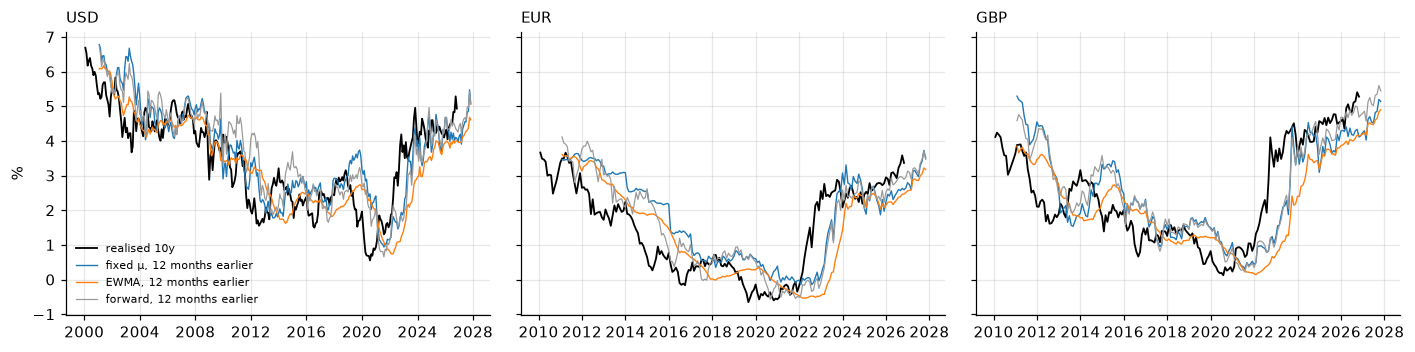

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, c in zip(axes, CCYS):
    ax.plot(y[c]["120m"].loc[FIRST_ORIGIN[c]:], color="k", lw=1.2, label="realised 10y")
    for ep in ENDPOINTS[c][:2]:
        n = label(None, ep, None)
        ax.plot(fc[c][n][12]["120m"].loc[FIRST_ORIGIN[c]:], lw=0.9, label=f"{EP_LABEL[ep]}, 12 months earlier")
    ax.plot(fc[c]["forwards"][12]["120m"].loc[FIRST_ORIGIN[c]:], lw=0.8, color="0.6", label="forward, 12 months earlier")
    ax.set_title(c, loc="left", fontsize=10)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=7, frameon=False); fig.tight_layout()

## 6. Model confidence set

The 90% model confidence set over **every** model in notebooks 02–05: the
step 7b variants, the other step 7 models (λ estimated, full macro,
shrinkage), the two-step models, the random walk and forwards. It contains
the best model with 90% probability, so a model outside it is beaten by the
others jointly, not just in one pairwise test chosen after the fact.

Loss is the squared error; the 'all' column averages it over the maturities
shown. GBP forwards have no h = 1 forecasts beyond 2 years, so they are
left out of those columns. The second table gives the MCS p-values (pooled
loss) of the plain models, their AR(1) versions and the two benchmarks: a
model is in the set when p >= 0.10.

In [9]:
SHORT = "3m / 6m (GBP)"
mcs = {(c, h): mcs_table({n: f[h] for n, f in fc[c].items()}, after(c, h), h, SHOW[c], n_boot=2000)
               .rename(columns={SHOW[c][0]: SHORT})
       for c in CCYS for h in H}
summary = {(c, f"h = {h}"): {col: f"{int((t[col] >= 0.10).sum())} / {int(t[col].notna().sum())}" for col in t.columns}
           for (c, h), t in mcs.items()}
display(pd.DataFrame(summary).T.style.set_caption("Models in the 90% MCS / models compared").set_table_styles(
    [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]))

In [10]:
# h = 1, pooled loss: which models survive, and the MCS p-values of the plain models and benchmarks
keep = {c: list(mcs[(c, 1)].index[mcs[(c, 1)]["all"] >= 0.10]) for c in CCYS}
for c in CCYS:
    print(f"{c}, h = 1, all maturities: {len(keep[c])} models in the 90% set:\n   " + "\n   ".join(keep[c]))
show = [label(None, None, None), label(None, None, "ar1"), label(("policy_rate",), None, None),
        label(("policy_rate",), None, "ar1"), "random walk", "forwards"]
pd.DataFrame({(c, f"h = {h}"): mcs[(c, h)].loc[show, "all"] for c in CCYS for h in H}).round(2)

USD, h = 1, all maturities: 20 models in the 90% set:
   yields: fixed μ + AR(1)
   yields: fixed μ + AR(1) with mean
   yields: EWMA + AR(1)
   yields: EWMA + AR(1) with mean
   yields: SPF 10y yield + AR(1)
   yields: SPF 10y yield + AR(1) with mean
   yields: SPF 10y CPI + AR(1)
   yields: SPF 10y CPI + AR(1) with mean
   policy rate: fixed μ + AR(1)
   policy rate: fixed μ + AR(1) with mean
   policy rate: EWMA + AR(1)
   policy rate: EWMA + AR(1) with mean
   policy rate: SPF 10y yield + AR(1)
   policy rate: SPF 10y yield + AR(1) with mean
   policy rate: SPF 10y CPI + AR(1)
   policy rate: SPF 10y CPI + AR(1) with mean
   step 7: yields, λ est.
   two-step VAR(1)
   random walk
   forwards
EUR, h = 1, all maturities: 17 models in the 90% set:
   yields: fixed μ + AR(1)
   yields: fixed μ + AR(1) with mean
   yields: EWMA + AR(1)
   yields: EWMA + AR(1) with mean
   yields: ECB SPF HICP + AR(1)
   yields: ECB SPF HICP + AR(1) with mean
   policy rate: fixed μ + AR(1)
   policy ra

USD                EUR                GBP  \
                             h = 1 h = 6 h = 12 h = 1 h = 6 h = 12 h = 1   
model                                                                      
yields: fixed μ               0.02  0.99    1.0  0.00  0.82   0.77  0.06   
yields: fixed μ + AR(1)       0.81  0.99    1.0  0.46  0.82   0.77  0.74   
policy rate: fixed μ          0.02  0.99    1.0  0.00  0.82   0.67  0.02   
policy rate: fixed μ + AR(1)  0.82  0.99    1.0  0.46  0.80   0.62  0.74   
random walk                   0.81  0.99    1.0  0.57  0.82   0.95  1.00   
forwards                      1.00  0.99    1.0  1.00  1.00   1.00   NaN   

                                           
                             h = 6 h = 12  
model                                      
yields: fixed μ               0.81   0.86  
yields: fixed μ + AR(1)       0.81   0.86  
policy rate: fixed μ          0.71   0.86  
policy rate: fixed μ + AR(1)  0.71   0.86  
random walk                   1.00   1.00  
forwards                      0.95   0.86

## 7. Takeaways

1. **Persistent fitting errors: the AR(1) fixes the one-month forecasts, and
   only those.**
   - **Gains at h = 1.** The AR(1) cuts RMSE significantly (Clark–West, 1%;
     GBP 5y 5–10%) at both ends of the curve in every currency. For the fixed-μ models:

     | Currency | Short end | Long end |
     |---|---|---|
     | USD | 3m −11 to −18% | 10y −11 to −13% |
     | EUR | 3m −20 to −33% | 5y −11 to −13% |
     | GBP | 6m −10 to −26% | 10y −16% |

   - **Confidence set.** At h = 1, the 90% set on the pooled loss keeps every
     AR(1) variant. It drops the plain λ-fixed models (p = 0.00–0.06) in all
     three currencies, along with the endpoint, full macro and shrinkage
     models without AR(1) errors. Only the λ-estimated model survives
     without them.
   - **Against forwards at h = 1:**
     - USD 10y goes from 1.13*** to 1.00, and USD 3m from 1.22–1.27*** to
       1.03–1.09.
     - The euro and sterling short ends still lose clearly: EUR 3m 1.61–1.74,
       GBP 6m 1.59–1.97.
   - **No gain at h = 12.** Ratios are 0.96–1.07, slightly worse at the USD
     and EUR 10y. The residuals' half-lives are 1–6 months in USD and EUR,
     so ρ¹² is close to zero. The intercept (`ar1c`) adds little over `ar1`.
   - Raviv's (2013) ~31% gain at the 10y, h = 12, is **not** reproduced.
2. **Shifting endpoints: right in trends, wrong at the turn.**
   - **`ewma` removes most of the rally bias** in the 10y forecasts at
     h = 12, for 2014–21:

     | | Fixed μ | `ewma` |
     |---|---|---|
     | USD | +45 bp | +2 bp |
     | EUR | +78 bp | +38 bp |
     | GBP | +42 bp | +14 bp |

   - **It overshoots when rates turn.** In 2022–26 it under-predicted by 110–151 bp,
     against 56–93 bp with fixed μ. The endpoint lags, and μ_level (the
     average gap between the level and its trailing mean) is negative over a
     falling-rate sample, so the model extrapolates the trend.
   - **Net effect on the 10y at h = 12** (none significant):

     | | Ratio to fixed μ |
     |---|---|
     | USD | 0.97 |
     | EUR | 1.00 |
     | GBP | 1.06 |

   - **US surveys make things worse.** The SPF expected 10y yield and 10y
     CPI raise the 10y bias (2014–21: +63 / +80 bp against +45). At 5y,
     h = 12, they are 7–17% worse than fixed μ, significantly so for CPI10.
     Forecasters expected normalisation just as the model did.
   - **The ECB long-term HICP expectation helps a little.** Short and medium
     maturities at h = 12 improve by 2–4% (DM 5–10%). It does nothing for
     the 10y bias (+93 bp in 2010–13, against +92). Inflation expectations
     barely moved (1.7–2.0%) while real rates fell. An anchor that tracks
     falling rates needs r* as well (Bauer & Rudebusch 2020), and no
     real-time public r* series is in the data yet.
   - van Dijk et al.'s 0.77 × random walk at the 10y, h = 12, is **not**
     reproduced. The best here is USD `ewma`, at 1.07 × random walk.
3. **At 6–12 months the problem is unchanged.**
   - No variant beats forwards or the random walk significantly.
   - The confidence set keeps 20–34 of 22–34 models at every maturity, so
     the data cannot rank them.
   - The remaining gap is failure 4: the forward curve knows the expected
     policy path.
4. **What carries forward.**
   - **The AR(1) error correction becomes part of the model:** `ar1`, the
     simpler of the two, for h = 1 forecasts and the trading signal (step 8).
   - **Endpoints are not adopted as a default.** `ewma` is worth keeping as
     a variant: it fixes bias in trending years, which matters for a
     duration signal, but fails at turning points.
   - **Next in step 7b:** forecast combination (item 3) and anchoring the
     short end to forwards (item 4). Both target h = 6–12, where the losses
     are.